In [9]:
import numpy as np
from itertools import combinations
from qiskit.quantum_info import Statevector
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from qiskit.quantum_info import Operator



In [2]:
#pip install pylatexenc

In [3]:
def generate_k_complement_pairs(N, k):
    """
    Yields pairs (S, Sc) where:
    S  = combination of k numbers from 0..N-1
    Sc = complement of S
    """
    full_set = set(range(N))
    
    for comb in combinations(range(N), k):
        S = set(comb)
        Sc = full_set - S
        yield tuple(sorted(S)), tuple(sorted(Sc))

def find_k_complement_pairs(N, k):
    return list(generate_k_complement_pairs(N, k))

def phasor_state(k_vec):
    n = len(k_vec)
    Ph = []
    Ph_sign = []
    for k in range(0, n+1, 2):
        sign_ext = (-1)**(k/2)
        set_of_qubs = find_k_complement_pairs(n, k)
        #print(set_of_qubs)
        ll = len(set_of_qubs)
        for i_comp in range(ll):
            sign_int = 1
            Ph_comp = np.zeros(n)
            for i_list in set_of_qubs[i_comp][0]:
                #print(i_comp, i_list)
                #print(set_of_qubs[i_comp][0][i_list])
                sign_int =sign_int*k_vec[i_list]
                Ph_comp[i_list] = 1
            Ph.append(Ph_comp)
            Ph_sign.append(sign_int*sign_ext)
    return Ph, Ph_sign

def R_op(Phasor, i_q):
    ll = len(Phasor[0])
    for i in range(ll):
        st = Phasor[0][i]
        if st[0] == 0:
            st[0] = 1
            Phasor[0][i] = st
        else:
            st[0] = 0
            Phasor[0][i] = st
            Phasor[1][i] = Phasor[1][i] * (-1)
    return Phasor

In [4]:
pp = phasor_state([1,1])
print(pp)
pp1 = R_op(pp, 1)
print(pp1)

([array([0., 0.]), array([1., 1.])], [1.0, -1.0])
([array([1., 0.]), array([0., 1.])], [1.0, 1.0])


In [5]:
#pip install qiskit

In [6]:
import qiskit

In [59]:
import numpy as np
from qiskit import QuantumCircuit

def chain_controlled_y_circuit(n, k_vec):
    """
    n qubits (0..n-1):
      - H on qubit n-1
      - for j = n-2 down to 0:
          apply CRY( k_vec[j] * pi/2 ) with control=j, target=j+1
    """
    if n < 2:
        raise ValueError("n must be >= 2.")
    if len(k_vec) != n:
        raise ValueError(f"k_vec must have length n = {n}.")
    if any(k not in (-1, 1) for k in k_vec):
        raise ValueError("All entries of k_vec must be either +1 or -1.")

    qc = QuantumCircuit(n, name="H + chain CRY(pi)")

    #qc.y(0)

    for i in range(0,n-1):
        if k_vec[i] == 1:
            qc.x(i)
    if k_vec[n-1] == -1:
        qc.x(n-1)
    for i in range(n):
        qc.h(i)

    for j in range(n - 2, -1, -1):
        theta = np.pi
        qc.cry(theta, j, j + 1)

    theta = -np.pi/2
    #qc.y(0,1)
    #qc.swap(0,2)
    #qc.cz(0,1)
    #qc.ry(theta, 0)
    #qc.ry(theta/3, 2)
    
    return qc
    

from qiskit.quantum_info import Statevector
import numpy as np

def print_nonzero_amplitudes(qc, tol=1e-10):
    """
    Prints non-zero amplitudes of the statevector
    with qubit 0 on the left and qubit n-1 on the right.
    """
    psi = Statevector.from_instruction(qc)
    n = qc.num_qubits

    for idx, amp in enumerate(psi.data):
        if abs(amp) > tol:
            # Qiskit bit order is little-endian:
            # index -> |q_{n-1} ... q_0>
            bitstring_le = format(idx, f"0{n}b")
            
            # Reverse to show |q0 q1 ... q_{n-1}>
            bitstring = bitstring_le[::-1]
            #bitstring = bitstring_le
            print(f"|{bitstring}> : {amp}")

    return psi


# build your circuit
n = 3
k_vec = [1, 1, 1]
qc = chain_controlled_y_circuit(n, k_vec)
qc.draw("mpl")
# Get final statevector
#psi = Statevector.from_instruction(qc)

# Print full wavefunction
psi = print_nonzero_amplitudes(qc)
#print(psi)

|000> : (0.3535533905932737+0j)
|100> : (0.3535533905932737+0j)
|010> : (0.3535533905932737+0j)
|110> : (-0.3535533905932737+0j)
|001> : (0.3535533905932737+0j)
|101> : (-0.3535533905932737+0j)
|011> : (-0.3535533905932737+0j)
|111> : (-0.3535533905932737+0j)


In [60]:
# Convert to matrix
U = Operator(qc).data
np.set_printoptions(precision=1, suppress=True)
print((np.real(U)/np.abs(np.max(U))+1)/2)

[[1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 0. 0. 1. 0. 1. 1. 0.]
 [1. 1. 0. 0. 0. 0. 1. 1.]
 [0. 1. 0. 1. 0. 1. 0. 1.]
 [1. 1. 1. 1. 0. 0. 0. 0.]
 [0. 1. 1. 0. 0. 1. 1. 0.]
 [0. 0. 1. 1. 0. 0. 1. 1.]
 [0. 1. 0. 1. 1. 0. 1. 0.]]


In [46]:
U

array([[ 5.55111512e-17+0.j,  3.53553391e-01+0.j,  3.53553391e-01+0.j,
         2.77555756e-17+0.j,  3.53553391e-01+0.j, -2.77555756e-17+0.j,
         2.77555756e-17+0.j,  3.53553391e-01+0.j,  3.53553391e-01+0.j,
        -5.55111512e-17+0.j, -2.77555756e-17+0.j,  3.53553391e-01+0.j,
         2.77555756e-17+0.j,  3.53553391e-01+0.j,  3.53553391e-01+0.j,
        -2.77555756e-17+0.j],
       [-3.53553391e-01+0.j, -5.55111512e-17+0.j, -2.77555756e-17+0.j,
        -3.53553391e-01+0.j,  2.77555756e-17+0.j, -3.53553391e-01+0.j,
        -3.53553391e-01+0.j, -2.77555756e-17+0.j,  5.55111512e-17+0.j,
        -3.53553391e-01+0.j, -3.53553391e-01+0.j,  2.77555756e-17+0.j,
        -3.53553391e-01+0.j, -2.77555756e-17+0.j,  2.77555756e-17+0.j,
        -3.53553391e-01+0.j],
       [ 3.53553391e-01+0.j, -8.32667268e-17+0.j,  2.77555756e-17+0.j,
        -3.53553391e-01+0.j, -2.77555756e-17+0.j, -3.53553391e-01+0.j,
         3.53553391e-01+0.j, -2.77555756e-17+0.j, -5.55111512e-17+0.j,
        -3.535533

In [386]:
|0000> : (0.24999999999999992+0j)
|1000> : (0.24999999999999983+0j)
|0100> : (0.24999999999999986+0j)
|1100> : (0.24999999999999994+0j)
|0010> : (0.2499999999999999+0j)
|1010> : (-0.24999999999999997+0j)
|0110> : (-0.24999999999999994+0j)
|1110> : (0.24999999999999986+0j)
|0001> : (0.24999999999999992+0j)
|1001> : (-0.25+0j)
|0101> : (-0.24999999999999997+0j)
|1101> : (0.2499999999999999+0j)
|0011> : (-0.24999999999999994+0j)
|1011> : (-0.24999999999999986+0j)
|0111> : (-0.2499999999999999+0j)
|1111> : (-0.24999999999999997+0j)

SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (2512341084.py, line 3)

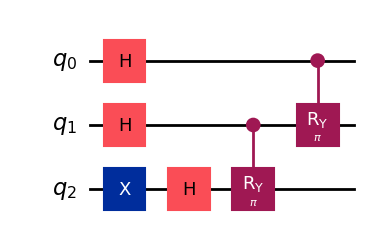

In [33]:
qc.draw("mpl")

In [382]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from qiskit.quantum_info import Statevector

def plot_wavefunction_signs(qc, tol=1e-10):
    """
    Plot sign of non-zero amplitudes vs computational basis index.
    Vertical lines connect each point to the horizontal axis.
    Only integer ticks are shown on x-axis.
    """
    psi = Statevector.from_instruction(qc).data

    indices = []
    signs = []

    for idx, amp in enumerate(psi):
        if abs(amp) > tol:
            indices.append(idx)
            signs.append(np.sign(np.real(amp)))

    indices = np.array(indices)
    signs = np.array(signs)

    fig, ax = plt.subplots(figsize=(10, 4))

    ax.vlines(indices, 0, signs)
    ax.scatter(indices, signs)

    ax.axhline(0, linestyle='--')
    ax.set_yticks([-1, 1])

    ax.set_xlabel("Computational Basis State (decimal)")
    ax.set_ylabel("Sign of Amplitude")
    ax.set_title("Wavefunction Sign Structure")

    # Force integer ticks
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

    ax.grid(True, linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.show()

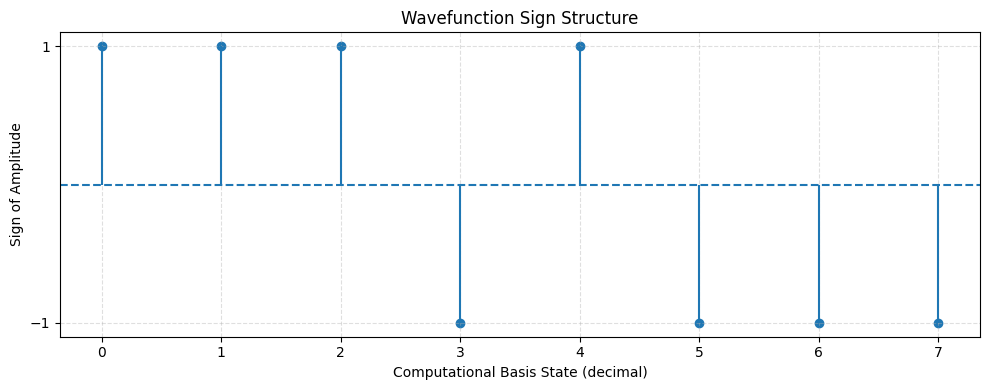

In [383]:
plot_wavefunction_signs(qc, tol=1e-10)